   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


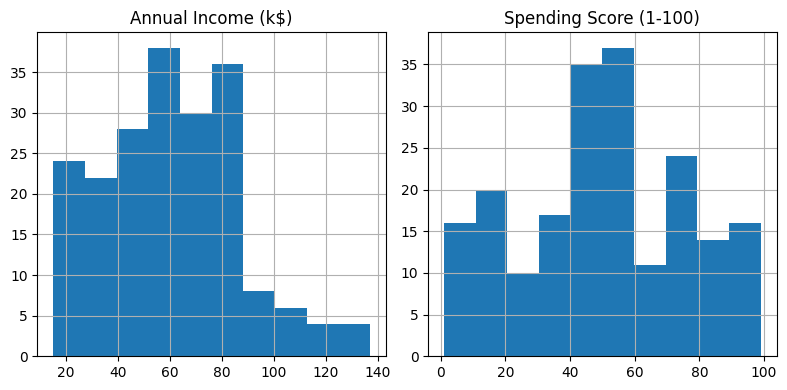

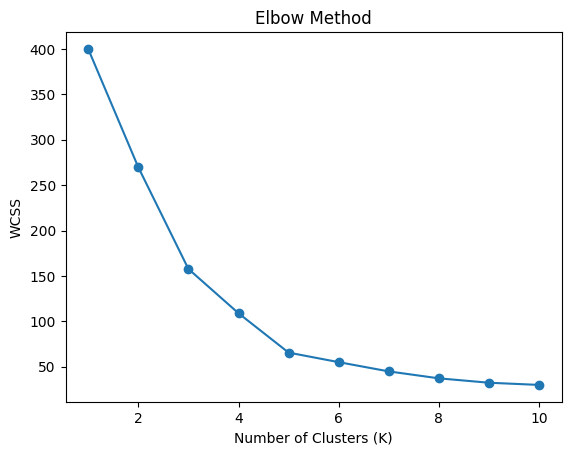

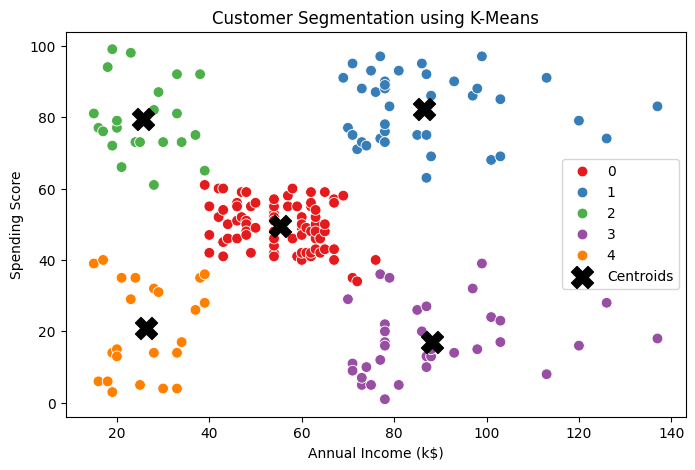


Customer Segment Characteristics:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset
df = pd.read_csv("Mall_Customers.csv")
print(df.head())

# 2. Inspect missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Select required features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# 3. Inspect feature distributions
X.hist(figsize=(8, 4))
plt.tight_layout()
plt.show()

# 4. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 6. Apply K-Means with K = 5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataset
df["Cluster"] = clusters

# Convert centroids back to original scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# 7. Plot clusters and centroids
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X["Annual Income (k$)"],
    y=X["Spending Score (1-100)"],
    hue=df["Cluster"],
    palette="Set1",
    s=60
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")
plt.legend()
plt.show()

# 8. Describe each customer segment
print("\nCustomer Segment Characteristics:")
print(df.groupby("Cluster")[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2))
